Estudo de Caso – Rede de Oficinas Automotivas

PARTE 1 – IMPORTAÇÃO E EXPLORAÇÃO DOS 
DADOS 
1. Importe as bibliotecas necessárias para realizar a atividade. 
2. Informe no código o caminho do arquivo Excel disponibilizado. 
3. Faça a leitura da planilha utilizando o Pandas. 
4. Mostre os primeiros registros do DataFrame. 
5. Mostre a quantidade de linhas e colunas existentes no dataset. 
6. Mostre os nomes das colunas disponíveis no dataset. 

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
df = pd.read_excel(r"C:\Users\Public\Dataset_Prova_Oficinas_50mil.xlsx")

In [10]:
print(df.head())
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

   id_ordem data_servico         cliente          cidade              oficina  \
0       NaN          NaN             NaN             NaN                  NaN   
1  OS000002   05/09/2026  Cliente 000002       CEILÂNDIA  Auto Center Central   
2  OS000003   07/03/2025  Cliente 000003   Águas Claras       Auto Center Sul   
3  OS000004   20/05/2025  Cliente 000004    ÁGUAS CLARAS  Auto Center Central   
4  OS000005   08/12/2025  Cliente 000005       Samambaia        Oficina Prime   

               categoria             servico tipo_veiculo valor_servico  \
0                    NaN                 NaN          NaN           NaN   
1        Ar-condicionado  Higienização do Ar       Picape        144,84   
2               Elétrica    Motor de Partida        Hatch        778,53   
3          Pneus e Rodas         Alinhamento          SUV      R$ 99,43   
4  Manutenção Preventiva       Troca de Óleo       Picape        391,80   

   quantidade    forma_pagamento  
0         NaN              

In [11]:
print(df.columns)

Index(['id_ordem', 'data_servico', 'cliente', 'cidade', 'oficina', 'categoria',
       'servico', 'tipo_veiculo', 'valor_servico', 'quantidade',
       'forma_pagamento'],
      dtype='str')


PARTE 2 – TRATAMENTO DOS DADOS – ETL 
Realize os seguintes tratamentos: 
1. Remova as linhas que estejam totalmente vazias. 
2. Padronize a coluna cidade, realizando os tratamentos necessários para: 
○ remover espaços extras; 
○ corrigir diferenças entre letras maiúsculas e minúsculas. 
3. Faça o tratamento da coluna valor_servico, removendo os caracteres utilizados 
na representação monetária e preparando os valores para conversão. 
4. Converta a coluna valor_servico para um tipo de dado numérico. 
5. Converta a coluna data_servico para o formato de data. 
6. Durante a conversão, faça com que datas inválidas sejam transformadas em 
valores nulos. 
7. Identifique e mostre a quantidade de registros duplicados existentes no dataset. 
8. Remova os registros duplicados. 
9. Identifique valores negativos existentes na coluna quantidade e realize o 
tratamento adequado. 
10. Ao final do processo de ETL, mostre novamente os primeiros registros do 
DataFrame. 

In [16]:
df = df.dropna(how="all")
df["cidade"] = df["cidade"].astype("string")
df["cidade"] = df["cidade"].str.strip()
df["cidade"] = df["cidade"].str.lower().str.title()
df["valor_servico"] = (
    df["valor_servico"]
    .str.replace("R$", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    )
print(df["valor_servico"].head())

1      14484
2      77853
3       9943
4      39180
5     111850
Name: valor_servico, dtype: str


In [27]:
df["data_servico"] = pd.to_datetime(
    df["data_servico"],
    dayfirst=True,
    format="mixed",
    errors="coerce"
).dt.date
print(df["data_servico"].head())




1    2026-09-05
2    2025-03-07
3    2025-05-20
4    2025-12-08
5    2026-08-29
Name: data_servico, dtype: object


In [28]:
print(f"Valores Duplicados: {df.duplicated().sum()}")
df = df.drop_duplicates()

Valores Duplicados: 645


In [34]:
df["quantidade"] = df["quantidade"].astype("string")
df["quantidade"] = (
    df["quantidade"]
    .str.replace("-", "", regex=False)
    )
df["quantidade"] = df["quantidade"].astype("float")
print(df['quantidade'].head())

1    2.0
2    1.0
3    2.0
4    1.0
5    3.0
Name: quantidade, dtype: float64


In [35]:
print(df.head())

   id_ordem data_servico         cliente        cidade              oficina  \
1  OS000002   2026-09-05  Cliente 000002     Ceilândia  Auto Center Central   
2  OS000003   2025-03-07  Cliente 000003  Águas Claras      Auto Center Sul   
3  OS000004   2025-05-20  Cliente 000004  Águas Claras  Auto Center Central   
4  OS000005   2025-12-08  Cliente 000005     Samambaia        Oficina Prime   
5  OS000006   2026-08-29  Cliente 000006     Ceilândia  Auto Center Central   

               categoria             servico tipo_veiculo valor_servico  \
1        Ar-condicionado  Higienização do Ar       Picape         14484   
2               Elétrica    Motor de Partida        Hatch         77853   
3          Pneus e Rodas         Alinhamento          SUV          9943   
4  Manutenção Preventiva       Troca de Óleo       Picape         39180   
5               Elétrica          Alternador   Utilitário        111850   

   quantidade    forma_pagamento  
1         2.0                PIX  
2   

PARTE 3 – GRÁFICO: SERVIÇOS POR CATEGORIA 
Crie um gráfico de barras utilizando a coluna categoria que permita responder à 
seguinte pergunta: 
Qual categoria possui a maior quantidade de serviços realizados? 
O gráfico deverá apresentar: 
● título; 
● identificação do eixo X; 
● identificação do eixo Y; 
● rotação dos textos quando necessária; 
● organização adequada do layout. 

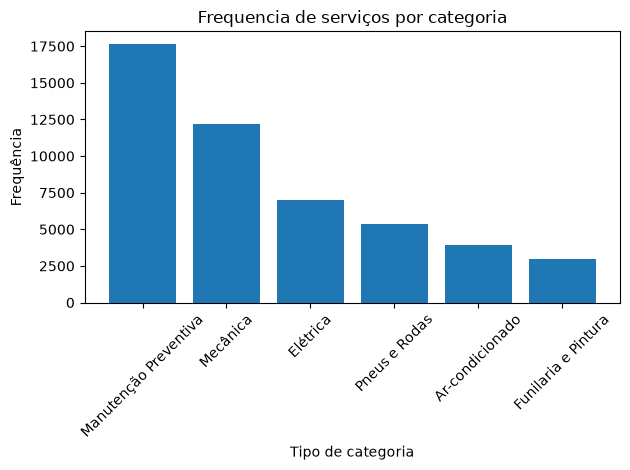

In [37]:
quantidade = df['categoria'].value_counts()

plt.bar(quantidade.index, quantidade.values)
plt.title('Frequencia de serviços por categoria')
plt.xlabel('Tipo de categoria')
plt.ylabel('Frequência')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A categoria de serviço "Manutenção Preventiva" é a que mais aparece na oficina

PARTE 4 – GRÁFICO: SERVIÇOS REALIZADOS 
Crie um gráfico de barras utilizando a coluna servico que permita responder: 
Quais são os serviços mais realizados pela rede de oficinas? 
O gráfico deverá permitir uma comparação visual clara entre os diferentes serviços. 

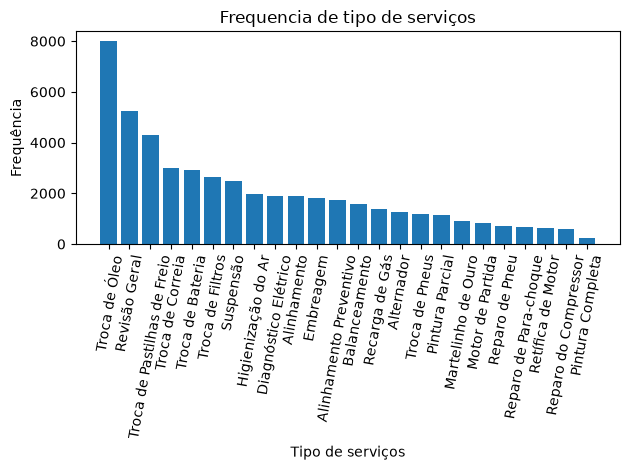

In [46]:
quantidade = df['servico'].value_counts()

plt.bar(quantidade.index, quantidade.values)
plt.title('Frequencia de tipo de serviços')
plt.xlabel('Tipo de serviços')
plt.ylabel('Frequência')
plt.xticks(rotation=80)
plt.tight_layout()
plt.show()

O serviço "Troca de Óleo" é o mais realizado na oficina.

PARTE 5 – GRÁFICO: SERVIÇOS POR CIDADE 
Utilizando a coluna cidade, crie um gráfico que permita responder: 
Em quais cidades ocorre a maior quantidade de serviços? 
O gráfico deverá possuir título e identificação adequada dos eixos. 

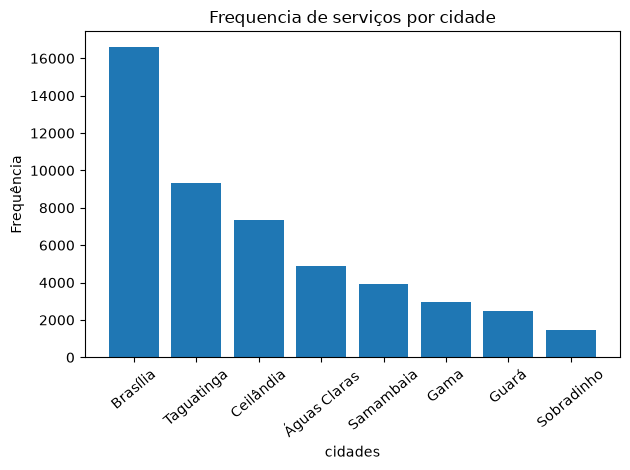

In [47]:
quantidade = df['cidade'].value_counts()

plt.bar(quantidade.index, quantidade.values)
plt.title('Frequencia de serviços por cidade')
plt.xlabel('cidades')
plt.ylabel('Frequência')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

Nas cidades "Brasília" e "Taguatinga" são onde ocorrem mais serviços, respectivamente.

PARTE 6 – GRÁFICO: FORMAS DE PAGAMENTO 
Utilizando a coluna forma_pagamento, crie um gráfico que permita responder: 
Qual é a forma de pagamento mais utilizada pelos clientes? 
Escolha um dos tipos de gráficos trabalhados em aula que você considere adequado para 
representar essas informações. 

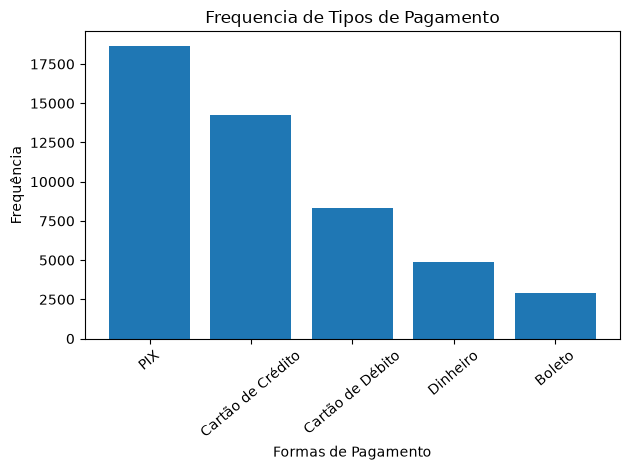

In [49]:
quantidade = df['forma_pagamento'].value_counts()

plt.bar(quantidade.index, quantidade.values)
plt.title('Frequencia de Tipos de Pagamento')
plt.xlabel('Formas de Pagamento')
plt.ylabel('Frequência')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

A forma de pagamento mais utilizada é o "PIX"

PARTE 7 – DESAFIO 
Utilizando as demais informações disponíveis no dataset, crie DOIS NOVOS GRÁFICOS 
diferentes dos quatro solicitados anteriormente. 
Você deverá definir o que deseja analisar.

Gráfico 1 (desafio): Quais são os tipos de veículos que mais aparecem na oficina?

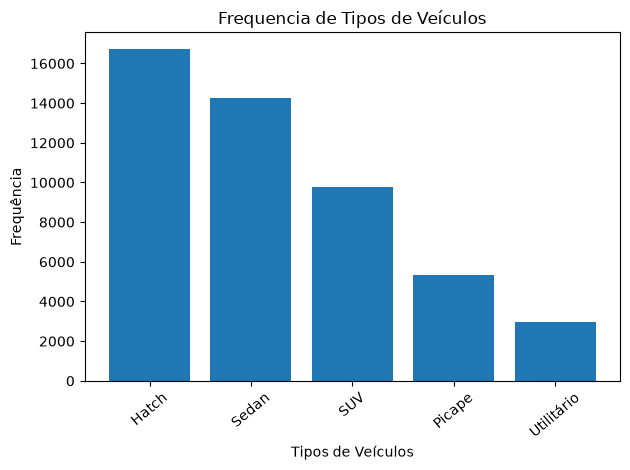

In [53]:
quantidade = df['tipo_veiculo'].value_counts()

plt.bar(quantidade.index, quantidade.values)
plt.title('Frequencia de Tipos de Veículos')
plt.xlabel('Tipos de Veículos')
plt.ylabel('Frequência')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()

Os tipos de veículos que mais aparecem são "Hatch" e "Sedan", respectivamente.

Gráfico 2 (desafio): Qual oficina com mais serviços registrados?

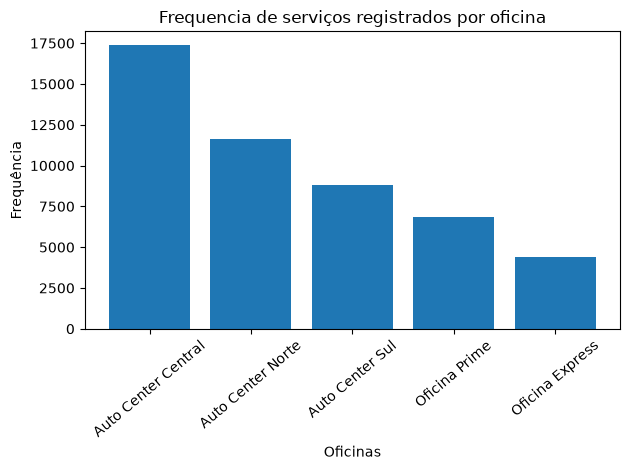

In [55]:
quantidade = df['oficina'].value_counts()

plt.bar(quantidade.index, quantidade.values)
plt.title('Frequencia de serviços registrados por oficina')
plt.xlabel('Oficinas')
plt.ylabel('Frequência')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()